# Predicting Early-Grade Reading Fluency in East Africa

**Mission:** To nurture compassionate and responsible young leaders by equipping children aged 7–12 with practical life skills, character development and opportunities to discover their talents through hands-on learning, mentorship and community service.

**Use case:** Predict how many words per minute a primary school child can read, so mentorship programs can find children who need reading support early.

**Dataset:** AHEAD (2008–2022), AFLEARN / DataFirst, University of Cape Town. DOI: https://doi.org/10.25828/2287-mw84

## 1. Import libraries
Tools for data, maths, charts, and reading the ZIP file.

In [2]:
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", font_scale=1.0)

## 2. Load the data
Load only the 11 columns I need, in small chunks, because the file is very large.

In [3]:
RAW_ZIP = "../data/afr-df-ahead-2008-2022-v2.zip"
RAW_CSV = "afr-df-ahead-2008-2022-v2.csv"

columns_we_need = [
    "country_iso", "admin_div1", "lang_assessment", "location",
    "gender", "age", "grade", "year",
    "fam_word_pm", "list_comp_score_pcnt", "oral_read_pm",
]

pieces = []
with zipfile.ZipFile(RAW_ZIP) as z:
    with z.open(RAW_CSV) as f:
        for chunk in pd.read_csv(f, usecols=columns_we_need, chunksize=20_000, low_memory=False):
            pieces.append(chunk)

raw = pd.concat(pieces, ignore_index=True)
print(raw.shape)

(217127, 11)


## 3. Clean the data
Turn columns into numbers, remove children with missing information, and keep realistic ages (5-14)

In [4]:
numeric_cols = ["lang_assessment", "location", "gender", "age", "grade",
                "year", "fam_word_pm", "list_comp_score_pcnt", "oral_read_pm"]
for col in numeric_cols:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

df = raw.dropna()
df = df[df["age"].between(5, 14) & (df["grade"] > 0)]
print(df.shape)


(24360, 11)


## 4. Give codes readable names
The dataset stores categories as numbers (for example 1 = Rural). I replace them with names and rename columns clearly.

In [5]:
df["country"] = df["country_iso"].map({"ET": "Ethiopia", "MW": "Malawi",
                                       "RW": "Rwanda", "TZ": "Tanzania"})
df["location"] = df["location"].map({1: "Rural", 2: "Urban"})
df["gender"] = df["gender"].map({0: "Male", 1: "Female"})
df["language"] = df["lang_assessment"].map({
    1: "Chichewa", 8: "Kinyarwanda", 9: "Kiswahili", 28: "Tigrinya",
    29: "Amharic", 30: "Afan Oromo", 31: "Somaligna",
    32: "Sidaamu Afoo", 33: "Hararigna"})

df = df.rename(columns={
    "admin_div1": "region",
    "fam_word_pm": "familiar_words_per_min",
    "list_comp_score_pcnt": "listening_comprehension_pct",
    "oral_read_pm": "words_per_minute"})

df["age"] = df["age"].astype(int)
df["grade"] = df["grade"].astype(int)
df["year"] = df["year"].astype(int)

df = df[["country", "region", "language", "location", "gender", "age", "grade",
         "year", "familiar_words_per_min", "listening_comprehension_pct",
         "words_per_minute"]]
df.head()

,country,region,language,location,gender,age,grade,year,familiar_words_per_min,listening_comprehension_pct,words_per_minute
38503,Ethiopia,1 - Tigray,Tigrinya,Urban,Female,9,3,2010,12.00000,100.000000,12.0
38504,Ethiopia,1 - Tigray,Tigrinya,Urban,Female,8,2,2010,0.00000,80.000001,0.0
38505,Ethiopia,1 - Tigray,Tigrinya,Urban,Male,8,2,2010,57.64706,100.000000,40.0
38506,Ethiopia,1 - Tigray,Tigrinya,Urban,Male,9,3,2010,29.00000,100.000000,18.0
38507,Ethiopia,1 - Tigray,Tigrinya,Urban,Male,10,2,2010,0.00000,100.000000,0.0


## 5. Save the clean dataset
Save the small clean table so it can go on GitHub and be used later by the API.

In [6]:
df.to_csv("../data/ahead_reading_fluency.csv", index=False)
print("Saved", len(df), "rows")

Saved 24360 rows


## 6. Correlation heatmap
Shows how strongly each number column moves together with reading speed.

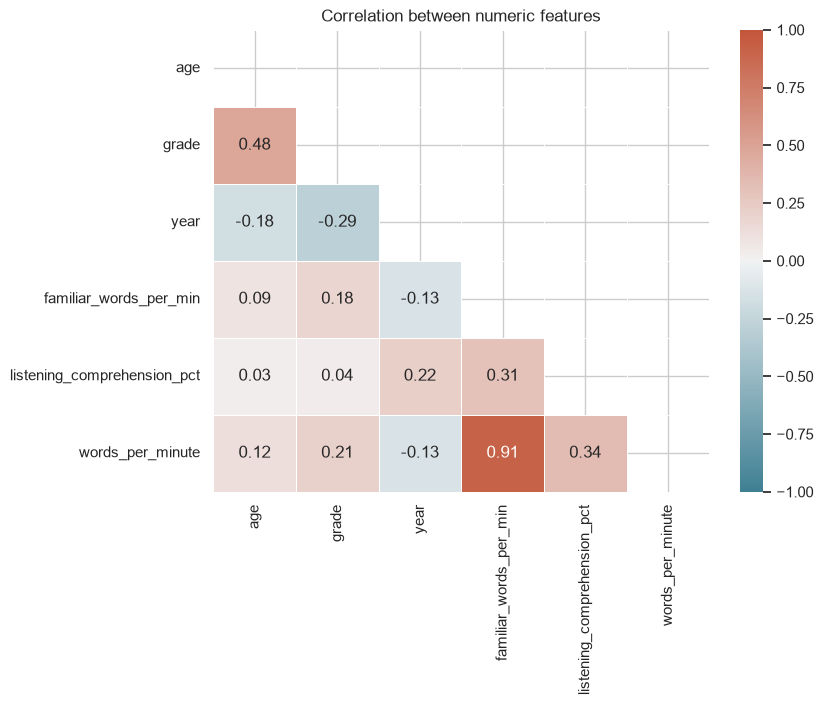

In [7]:
numeric_cols = ["age", "grade", "year", "familiar_words_per_min",
                "listening_comprehension_pct", "words_per_minute"]
corr = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap=sns.diverging_palette(220, 20, as_cmap=True),
            center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation between numeric features")
plt.show()

## 7. Distribution of reading speed
Shows how many children read at each speed.

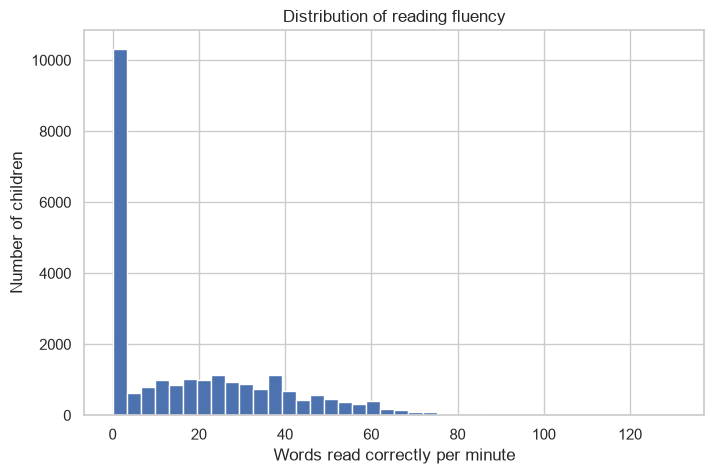

In [8]:
plt.figure(figsize=(8, 5))
plt.hist(df["words_per_minute"], bins=40, color="#4C72B0", edgecolor="white")
plt.xlabel("Words read correctly per minute")
plt.ylabel("Number of children")
plt.title("Distribution of reading fluency")
plt.show()

**What it shows:** Most children read very few words. About 40% of children read 0 words per minute, and only a few read more than 60. The distribution is skewed to the right.

**Decision:** Because of these extreme values, I will compare MSE with Huber loss, which is less sensitive to outliers.

## 8. Reading speed by country and location
Compares average reading speed across countries and between rural and urban schools.

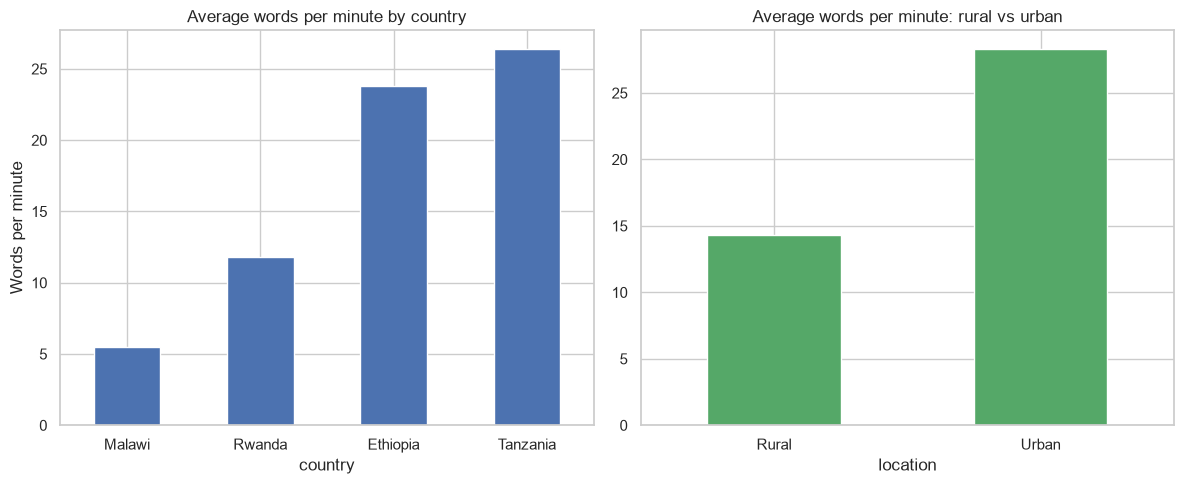

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df.groupby("country")["words_per_minute"].mean().sort_values().plot(
    kind="bar", ax=axes[0], color="#4C72B0", edgecolor="white")
axes[0].set_title("Average words per minute by country")
axes[0].set_ylabel("Words per minute")
axes[0].tick_params(axis="x", rotation=0)

df.groupby("location")["words_per_minute"].mean().plot(
    kind="bar", ax=axes[1], color="#55A868", edgecolor="white")
axes[1].set_title("Average words per minute: rural vs urban")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**What it shows:** Children in Tanzania and Ethiopia read faster than those in Rwanda and Malawi, and urban children read about twice as fast as rural children (28 vs 14 words per minute).

**Decision:** Country and location clearly affect reading, so I keep them as categorical features. I drop region, because it has 59 categories and mostly repeats the country information.

## 9. Feature engineering
I drop *region* (59 categories, mostly repeats country) and *year* (each country was tested in only one or two years). I keep 8 features: 4 categorical and 4 numeric.

In [10]:
categorical_features = ["country", "language", "location", "gender"]
numeric_features = ["age", "grade", "familiar_words_per_min", "listening_comprehension_pct"]

X = df[categorical_features + numeric_features]
y = df["words_per_minute"]
print(X.shape, y.shape)

(24360, 8) (24360,)


## 10. Split into train and test sets
80% of children for training, 20% kept aside for testing.

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(len(X_train), len(X_test))

19488 4872


## 11. Encode categories and standardize
Categories become numbers (one-hot encoding) and numeric features are standardized. Both are fitted on the training set only.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("numeric", StandardScaler(), numeric_features),
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)
print(X_train_prepared.shape)

(19488, 21)


## 12. Huber loss
Huber loss treats small errors like MSE (squared) but big errors linearly, so a few extreme children do not dominate the score. I use delta = 10 words per minute.

In [13]:
def huber_loss(y_true, y_pred, delta=10.0):
    error = np.asarray(y_true) - y_pred
    abs_error = np.abs(error)
    small = 0.5 * error ** 2
    big = delta * (abs_error - 0.5 * delta)
    return np.mean(np.where(abs_error <= delta, small, big))

## 13. Train and compare the models
Four required models, plus SGD trained with Huber loss for comparison. All evaluated on the same test set.

In [14]:
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

models = {
    "SGD (MSE loss)": SGDRegressor(loss="squared_error", max_iter=1000, random_state=42),
    "SGD (Huber loss)": SGDRegressor(loss="huber", epsilon=10.0, max_iter=1000, random_state=42),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}

results = []
for name, model in models.items():
    model.fit(X_train_prepared, y_train)
    train_pred = model.predict(X_train_prepared)
    test_pred = model.predict(X_test_prepared)
    results.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train, train_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Train Huber": huber_loss(y_train, train_pred),
        "Test Huber": huber_loss(y_test, test_pred),
    })

results_df = pd.DataFrame(results).round(1)
results_df

,Model,Train MSE,Test MSE,Train Huber,Test Huber
0,SGD (MSE loss),56.2,53.7,21.8,21.6
1,SGD (Huber loss),56.5,54.1,21.7,21.5
2,Linear Regression,56.2,53.6,21.8,21.6
3,Decision Tree,7.7,94.7,3.1,32.0
4,Random Forest,13.8,56.8,6.1,22.1


## 14. Reduce overfitting in the tree models
The decision tree and random forest memorised the training data (very low train MSE, much higher test MSE). I limit their depth so they learn general patterns instead.

In [15]:
tuned_tree_models = {
    "Decision Tree (max_depth=8)": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest (max_depth=12)": RandomForestRegressor(
        n_estimators=200, max_depth=12, min_samples_leaf=5, random_state=42, n_jobs=-1),
}

for name, model in tuned_tree_models.items():
    model.fit(X_train_prepared, y_train)
    train_pred = model.predict(X_train_prepared)
    test_pred = model.predict(X_test_prepared)
    results.append({
        "Model": name,
        "Train MSE": mean_squared_error(y_train, train_pred),
        "Test MSE": mean_squared_error(y_test, test_pred),
        "Train Huber": huber_loss(y_train, train_pred),
        "Test Huber": huber_loss(y_test, test_pred),
    })
    models[name] = model

results_df = pd.DataFrame(results).round(1).sort_values("Test MSE")
results_df

,Model,Train MSE,Test MSE,Train Huber,Test Huber
6,Random Forest (max_depth=12),38.7,47.0,15.7,19.0
5,Decision Tree (max_depth=8),47.6,53.0,18.8,20.5
2,Linear Regression,56.2,53.6,21.8,21.6
0,SGD (MSE loss),56.2,53.7,21.8,21.6
1,SGD (Huber loss),56.5,54.1,21.7,21.5
4,Random Forest,13.8,56.8,6.1,22.1
3,Decision Tree,7.7,94.7,3.1,32.0


**What the table shows:** The tuned Random Forest has the lowest test MSE (47.0, about 7 words per minute of error), so it is the best model. Linear Regression and SGD perform almost the same because they are both straight-line models. The untuned trees overfitted: they memorised the training data but did badly on the test set.

**MSE vs Huber:** SGD trained with Huber loss has a slightly better Huber score but a slightly worse MSE, because each model is best at the loss it was trained on. The small difference shows that extreme values do not strongly distort the linear model.

## 15. Tune SGDRegressor
I try different learning rates and regularization strengths, training each for 50 epochs, and compare their test MSE.

In [19]:
import warnings
warnings.filterwarnings("ignore")

tuning_results = []
for learning_rate in [0.0001, 0.001, 0.01, 0.1]:
    for alpha in [0.0001, 0.01, 1.0]:
        sgd = SGDRegressor(learning_rate="constant", eta0=learning_rate,
                           alpha=alpha, random_state=42)
        for epoch in range(50):
            sgd.partial_fit(X_train_prepared, y_train)
        tuning_results.append({
            "Learning rate": learning_rate,
            "Alpha (regularization)": alpha,
            "Test MSE": mean_squared_error(y_test, sgd.predict(X_test_prepared)),
        })

pd.DataFrame(tuning_results).round({"Test MSE": 2}).sort_values("Test MSE")

,Learning rate,Alpha (regularization),Test MSE
0,0.0001,0.0001,53.70
3,0.0010,0.0001,54.09
1,0.0001,0.0100,54.17
4,0.0010,0.0100,54.54
6,0.0100,0.0001,55.75
7,0.0100,0.0100,56.24
10,0.1000,0.0100,74.52
9,0.1000,0.0001,77.80
2,0.0001,1.0000,138.87
5,0.0010,1.0000,143.46


**What it shows:** The best result comes from a small learning rate (0.0001) and a light brake (alpha 0.0001), with a test MSE of 53.70. When the learning rate is too big (0.1), the model jumps around and the error goes up. When alpha is too strong (1.0), the model becomes too simple and the error more than doubles.

**Decision:** I use learning rate 0.0001 and alpha 0.0001.

## 16. Loss curve
Train and test MSE after every epoch for the best SGD settings.

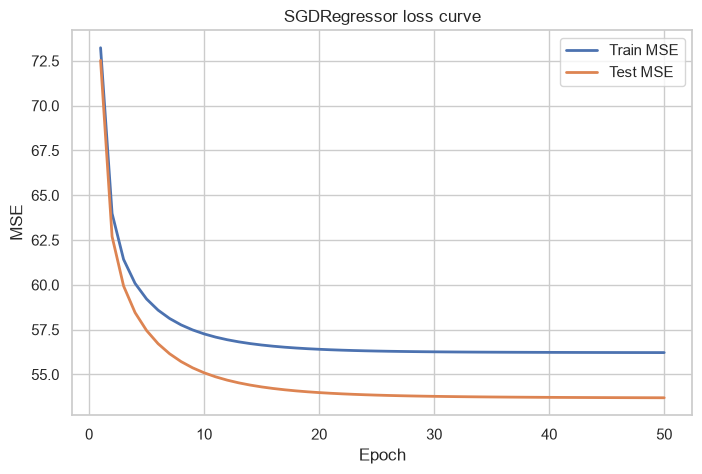

In [20]:
sgd_best = SGDRegressor(learning_rate="constant", eta0=0.0001,
                        alpha=0.0001, random_state=42)
train_losses, test_losses = [], []

for epoch in range(50):
    sgd_best.partial_fit(X_train_prepared, y_train)
    train_losses.append(mean_squared_error(y_train, sgd_best.predict(X_train_prepared)))
    test_losses.append(mean_squared_error(y_test, sgd_best.predict(X_test_prepared)))

plt.figure(figsize=(8, 5))
plt.plot(range(1, 51), train_losses, label="Train MSE", color="#4C72B0", linewidth=2)
plt.plot(range(1, 51), test_losses, label="Test MSE", color="#DD8452", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("SGDRegressor loss curve")
plt.legend()
plt.show()

**What it shows:** The error drops fast in the first few epochs, then levels off after about 20, so training longer does not help much. The train and test lines stay close, which means the model is not overfitting.

**Decision:** About 20–30 epochs are enough. I kept 50 to show the curve fully flattening.

## 17. Scatter plots: before and after
The feature most correlated with reading speed (familiar words per minute) against the target, then the same plot with a fitted regression line.

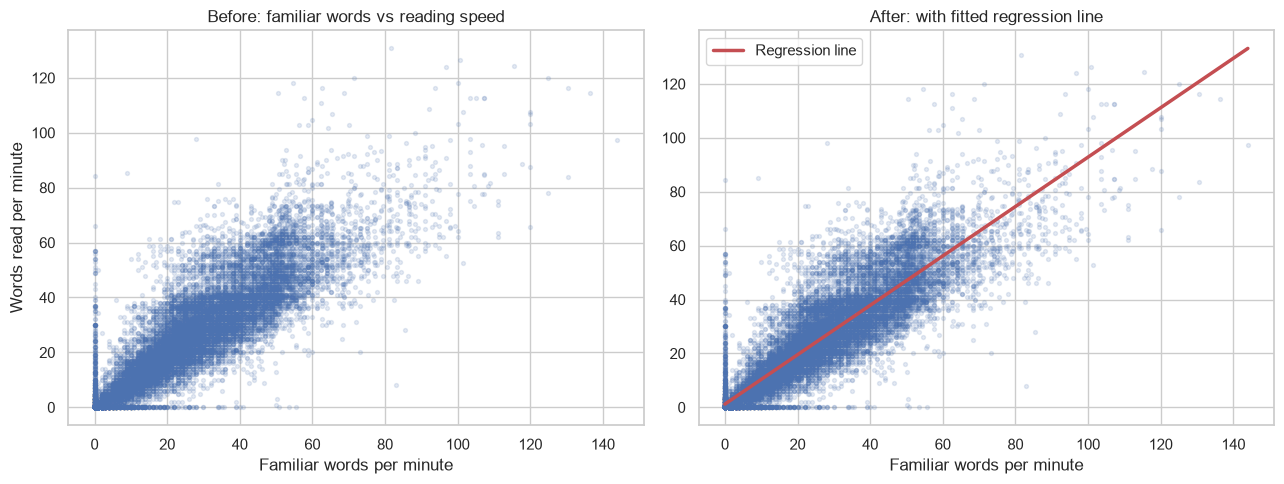

In [21]:
from sklearn.linear_model import LinearRegression

x_feature = df[["familiar_words_per_min"]]
line_model = LinearRegression().fit(x_feature, y)
x_line = np.linspace(x_feature.min().iloc[0], x_feature.max().iloc[0], 100).reshape(-1, 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(x_feature, y, alpha=0.15, s=8, color="#4C72B0")
axes[0].set_title("Before: familiar words vs reading speed")
axes[0].set_xlabel("Familiar words per minute")
axes[0].set_ylabel("Words read per minute")

axes[1].scatter(x_feature, y, alpha=0.15, s=8, color="#4C72B0")
axes[1].plot(x_line, line_model.predict(pd.DataFrame(x_line, columns=["familiar_words_per_min"])),
             color="#C44E52", linewidth=2.5, label="Regression line")
axes[1].set_title("After: with fitted regression line")
axes[1].set_xlabel("Familiar words per minute")
axes[1].legend()

plt.tight_layout()
plt.show()

**What it shows:** Children who read more familiar words also read stories faster, and the red line follows this upward trend well. The dots stuck at zero are children who could not read any words yet.

## 18. Choose and save the best model
The best model is the one with the lowest test MSE: the tuned Random Forest (test MSE 47.0, about 7 words per minute of error). It works better than the linear models because reading speed does not change in a perfectly straight line. I save it together with its preprocessing in one Pipeline.

In [22]:
import os
import joblib
from sklearn.pipeline import Pipeline

best_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", models["Random Forest (max_depth=12)"]),
])

os.makedirs("../API", exist_ok=True)
joblib.dump(best_model, "../API/best_model.pkl", compress=3)
print("Saved best model, test MSE:",
      round(mean_squared_error(y_test, best_model.predict(X_test)), 1))

Saved best model, test MSE: 47.0


## 19. Predict one row of the test set
A function that loads the saved model and predicts reading speed for one child from the test set. The API will reuse this.

In [23]:
def predict_one(row, model_path="../API/best_model.pkl"):
    model = joblib.load(model_path)
    return float(model.predict(row)[0])

one_child = X_test.iloc[[0]]
display(one_child)
print("Predicted words per minute:", round(predict_one(one_child), 1))
print("Actual words per minute:   ", y_test.iloc[0])

,country,language,location,gender,age,grade,familiar_words_per_min,listening_comprehension_pct
40570,Ethiopia,Amharic,Urban,Female,11,2,33.0,0.0


Predicted words per minute: 30.1
Actual words per minute:    20.0
